# Task 5 question 2

Train using all features created in taks 4 and hyperparameters tuning

I used ChatGPT to find specific functions, access quickly to documentation.

Example of prompt: What are already implemented functions for feature selection?

ChatGPT suggested functions and I looked up the online documentation.

Article on optimizing XGBoost
https://medium.com/@dicee/optimizing-xgboost-a-guide-to-hyperparameter-tuning-77b6e48e289d 

## Set up

In [1]:
import numpy as np
import pandas as pd

import xgboost as xgb
import matplotlib.pyplot as plt

from ift6758.milestone2.models.data import load_features, split_data_train, REPO_ROOT, TRAIN_SEASONS
from ift6758.milestone2.models.train_baselines import SEED,VALIDATION_SIZE, WANDB_ENTITY, WANDB_PROJECT, MODEL_DIR, FIGURE_DIR
from ift6758.milestone2.models.plot import roc_plot,goal_rate_plot,cumulative_goals_plot,plot_calibration

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif, SelectKBest, SelectPercentile, RFE, SequentialFeatureSelector
from sklearn.preprocessing import OneHotEncoder

In [2]:
# train using all features created in task 4
features = ['game_seconds','period','x_coord','y_coord','distance','angle',
            'shot_type','last_event_type','last_x_coord','last_y_coord',
            'time_from_last','distance_from_last','rebound','change_angle','speed']

In [3]:
df = load_features()

In [4]:
X_train, X_val, y_train, y_val = split_data_train(df, features, seed=SEED, validation_size=VALIDATION_SIZE)
probas = {}

In [5]:
X_train['shot_type'] = X_train['shot_type'].astype('category')
X_train['last_event_type'] = X_train['last_event_type'].astype('category')

X_val['shot_type'] = X_val['shot_type'].astype('category')
X_val['last_event_type'] = X_val['last_event_type'].astype('category')

In [6]:
X_train.dtypes

game_seconds             int64
period                   int64
x_coord                float64
y_coord                float64
distance               float64
angle                  float64
shot_type             category
last_event_type       category
last_x_coord           float64
last_y_coord           float64
time_from_last         float64
distance_from_last     float64
rebound                   bool
change_angle           float64
speed                  float64
dtype: object

## Tuning hyperparameters

In [6]:
#default hyperparameters
clf = xgb.XGBClassifier(enable_categorical = True,random_state=SEED)
clf.fit(X_train, y_train)

# for the figures
probas['default'] = clf.predict_proba(X_val)[:, -1]

In [7]:
#use grid with cross validation
def select_hyper(scoring,train,param_grid,model):
    """
    Find the best hyperparameters with the best score.

    param:
        scoring : metric to evaluate the hyperparameters
        train : Training set
        param_grid : Dictionnary of the hyperparameters and the values they can take
        model : Prediction model
    """
    param_grid = param_grid

    grid = GridSearchCV(
        model,
        param_grid,
        scoring=scoring,
        n_jobs=-1,
        cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED), #5-fold cross validation
        verbose = 1,
        refit = False
    )

    grid.fit(train, y_train)

    print(grid.best_params_)
    print(grid.best_score_)

    return
   

In [13]:
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.001],
    'subsample': [0.5, 0.7, 1.0]
}

In [14]:
select_hyper('accuracy',X_train,param_grid,clf)

select_hyper('roc_auc',X_train,param_grid,clf)

#calibration curve
select_hyper('neg_brier_score',X_train,param_grid,clf)

Fitting 5 folds for each of 27 candidates, totalling 135 fits
{'learning_rate': 0.1, 'max_depth': 7, 'subsample': 1.0}
0.9300798323458839
Fitting 5 folds for each of 27 candidates, totalling 135 fits
{'learning_rate': 0.1, 'max_depth': 7, 'subsample': 1.0}
0.851315047881932
Fitting 5 folds for each of 27 candidates, totalling 135 fits
{'learning_rate': 0.1, 'max_depth': 7, 'subsample': 1.0}
-0.05913659408688545


In [26]:
model = xgb.XGBClassifier(enable_categorical = True,random_state=SEED, learning_rate = 0.1, max_depth = 7, subsample=1.0) 
model.fit(X_train,y_train)
probas['hyper_selection'] = model.predict_proba(X_val)[:, -1]

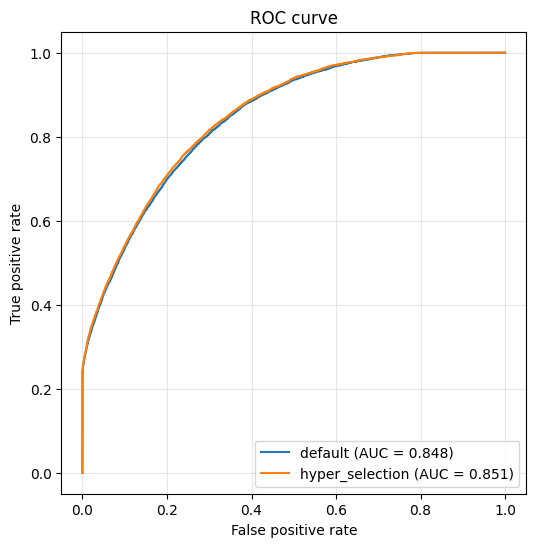

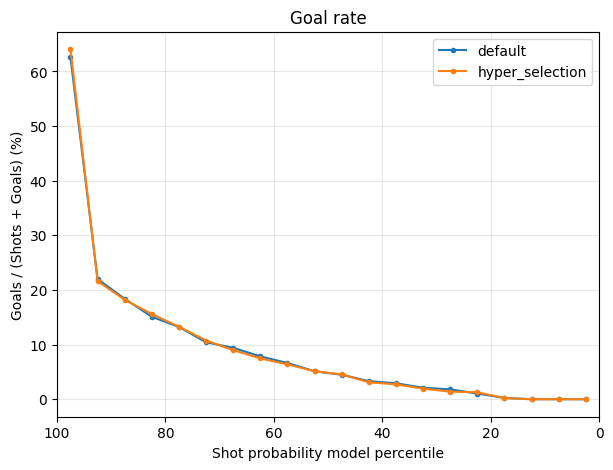

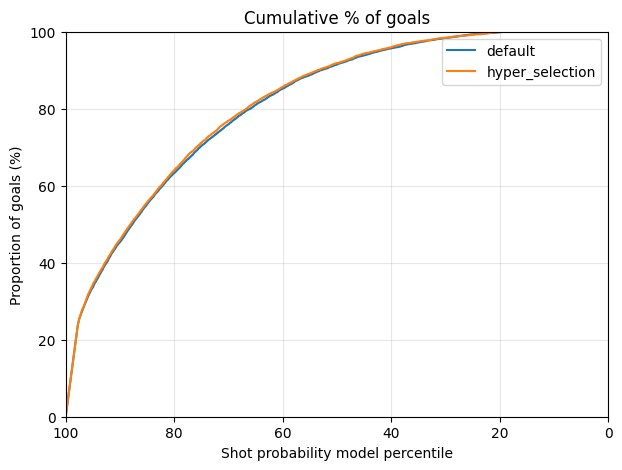

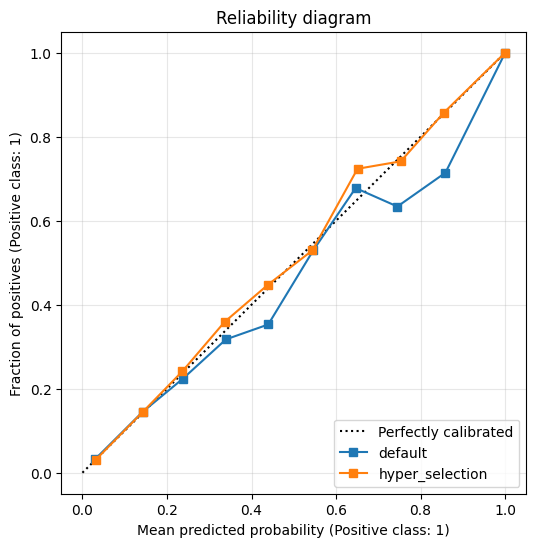

In [18]:
roc_plot(y_val,probas)
plt.savefig(FIGURE_DIR / "XGBoost_q2_roc.png", dpi=150)
plt.show()

goal_rate_plot(y_val,probas)
plt.show()

cumulative_goals_plot(y_val,probas)
plt.show()

plot_calibration(y_val,probas)
plt.savefig(FIGURE_DIR / "XGBoost_q2_calibration.png", dpi=150)
plt.show()

# Task 5 Question 3 : Feature Selection

In [27]:
# Reset probas
probas = {}
# We are starting with 15 features
X_train.shape

(399713, 15)

In [20]:
X_train

,game_seconds,period,x_coord,y_coord,distance,angle,shot_type,last_event_type,last_x_coord,last_y_coord,time_from_last,distance_from_last,rebound,change_angle,speed
212500,2839,3,-38.0,17.0,53.758720,18.434949,wrist,faceoff,-69.0,-22.0,9.0,49.819675,False,0.0,5.535519
7515,1009,1,80.0,19.0,21.023796,64.653824,wrist,missed-shot,38.0,-17.0,18.0,55.317267,False,0.0,3.073181
392993,2963,3,78.0,26.0,28.231188,67.067900,wrist,blocked-shot,52.0,-16.0,5.0,49.396356,False,0.0,9.879271
304001,3116,3,-34.0,21.0,58.872744,20.897765,wrist,hit,-57.0,-41.0,6.0,66.128662,False,0.0,11.021444
272878,1441,2,-73.0,-4.0,16.492423,14.036243,wrist,faceoff,0.0,0.0,6.0,73.109507,False,0.0,12.184918
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449256,693,1,-79.0,23.0,25.079872,66.501434,wrist,faceoff,-69.0,22.0,9.0,10.049876,False,0.0,1.116653
256728,3362,3,79.0,-6.0,11.661904,30.963757,tip-in,blocked-shot,54.0,-19.0,16.0,28.178006,False,0.0,1.761125
89320,3599,3,83.0,-36.0,36.496575,80.537678,wrist,blocked-shot,66.0,6.0,2.0,45.310043,False,0.0,22.655022
429154,1230,2,57.0,23.0,39.408121,35.706691,wrist,giveaway,-61.0,40.0,11.0,119.218287,False,0.0,10.838026


## Encoding categorial features

In [ ]:
def oneHotEncoding(sub,df_train,df_val):
    enc = OneHotEncoder()

    enc.fit(sub)
    cols = enc.categories_
    sub = pd.DataFrame(enc.transform(sub).toarray(),columns=cols[0])
    sub.index = df_train.index
    return sub

def encoding(df_train,df_val):
    shot_type = oneHotEncoding(pd.DataFrame(df['shot_type'],columns=['shot_type']),df)
    last_event_type = oneHotEncoding(pd.DataFrame(df['last_event_type'],columns=['last_event_type']),df)

    cols = df.columns
    cols = cols.append(shot_type.columns)
    cols = cols.append(last_event_type.columns)

    train = pd.concat([df,shot_type,last_event_type],axis=1)
    train.columns = cols
    train = train.drop(columns=['shot_type','last_event_type'])
    
    return train

In [23]:
# One hot encoding
train_ohe = encoding(X_train)
val_ohe = encoding(X_val)
train_ohe

,game_seconds,period,x_coord,y_coord,distance,angle,last_x_coord,last_y_coord,time_from_last,distance_from_last,...,wrist,blocked-shot,faceoff,giveaway,goal,hit,missed-shot,penalty,shot-on-goal,takeaway
212500,2839,3,-38.0,17.0,53.758720,18.434949,-69.0,-22.0,9.0,49.819675,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7515,1009,1,80.0,19.0,21.023796,64.653824,38.0,-17.0,18.0,55.317267,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
392993,2963,3,78.0,26.0,28.231188,67.067900,52.0,-16.0,5.0,49.396356,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
304001,3116,3,-34.0,21.0,58.872744,20.897765,-57.0,-41.0,6.0,66.128662,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
272878,1441,2,-73.0,-4.0,16.492423,14.036243,0.0,0.0,6.0,73.109507,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449256,693,1,-79.0,23.0,25.079872,66.501434,-69.0,22.0,9.0,10.049876,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
256728,3362,3,79.0,-6.0,11.661904,30.963757,54.0,-19.0,16.0,28.178006,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
89320,3599,3,83.0,-36.0,36.496575,80.537678,66.0,6.0,2.0,45.310043,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
429154,1230,2,57.0,23.0,39.408121,35.706691,-61.0,40.0,11.0,119.218287,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [29]:
val_ohe

,game_seconds,period,x_coord,y_coord,distance,angle,last_x_coord,last_y_coord,time_from_last,distance_from_last,...,wrap-around,wrist,blocked-shot,faceoff,giveaway,hit,missed-shot,penalty,shot-on-goal,takeaway
139242,524,1,-57.0,33.0,45.967380,45.881404,-81.0,-41.0,66.0,77.794601,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
167616,3064,3,-35.0,16.0,56.320511,16.504361,-67.0,-1.0,2.0,36.235342,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
154009,1250,2,-42.0,-25.0,53.235327,28.009177,-64.0,21.0,5.0,50.990195,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
309000,2319,2,-39.0,32.0,59.363288,32.619243,-72.0,-3.0,7.0,48.104054,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
351773,2286,2,-81.0,-23.0,24.351591,70.820992,-32.0,-39.0,5.0,51.546096,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39207,1954,2,-59.0,-16.0,34.000000,28.072487,-7.0,-26.0,1.0,52.952809,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
452266,2185,2,-78.0,-1.0,11.045361,5.194429,81.0,-1.0,11.0,159.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
380052,3385,3,-87.0,-26.0,26.076810,85.601295,-94.0,28.0,11.0,54.451814,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
77469,2012,2,82.0,-6.0,9.219544,40.601295,91.0,-30.0,61.0,25.632011,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [25]:
# make categorial features to type int
train_ord = X_train.copy()
val_ord = X_val.copy()

cat_cols = train_ord.select_dtypes(include=['category']).columns

for col in cat_cols:
    train_ord[col] = train_ord[col].astype('category')
    categories = train_ord[col].cat.categories

    val_ord[col] = pd.Categorical(
        val_ord[col],
        categories=categories
    )

    train_ord[col] = train_ord[col].cat.codes
    val_ord[col] = val_ord[col].cat.codes

train_ord

,game_seconds,period,x_coord,y_coord,distance,angle,shot_type,last_event_type,last_x_coord,last_y_coord,time_from_last,distance_from_last,rebound,change_angle,speed
212500,2839,3,-38.0,17.0,53.758720,18.434949,10,1,-69.0,-22.0,9.0,49.819675,False,0.0,5.535519
7515,1009,1,80.0,19.0,21.023796,64.653824,10,5,38.0,-17.0,18.0,55.317267,False,0.0,3.073181
392993,2963,3,78.0,26.0,28.231188,67.067900,10,0,52.0,-16.0,5.0,49.396356,False,0.0,9.879271
304001,3116,3,-34.0,21.0,58.872744,20.897765,10,4,-57.0,-41.0,6.0,66.128662,False,0.0,11.021444
272878,1441,2,-73.0,-4.0,16.492423,14.036243,10,1,0.0,0.0,6.0,73.109507,False,0.0,12.184918
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449256,693,1,-79.0,23.0,25.079872,66.501434,10,1,-69.0,22.0,9.0,10.049876,False,0.0,1.116653
256728,3362,3,79.0,-6.0,11.661904,30.963757,8,0,54.0,-19.0,16.0,28.178006,False,0.0,1.761125
89320,3599,3,83.0,-36.0,36.496575,80.537678,10,0,66.0,6.0,2.0,45.310043,False,0.0,22.655022
429154,1230,2,57.0,23.0,39.408121,35.706691,10,2,-61.0,40.0,11.0,119.218287,False,0.0,10.838026


In [28]:
model = xgb.XGBClassifier(enable_categorical = True,random_state=SEED, learning_rate = 0.1, max_depth = 7, subsample=1.0) 
model.fit(train_ord,y_train)
probas['ohe'] = model.predict_proba(val_ohe)[:, -1]

model.fit(train_ord,y_train)
probas['ordinal'] = model.predict_proba(val_ord)[:, -1]

ValueError: feature_names mismatch: ['game_seconds', 'period', 'x_coord', 'y_coord', 'distance', 'angle', 'shot_type', 'last_event_type', 'last_x_coord', 'last_y_coord', 'time_from_last', 'distance_from_last', 'rebound', 'change_angle', 'speed'] ['game_seconds', 'period', 'x_coord', 'y_coord', 'distance', 'angle', 'last_x_coord', 'last_y_coord', 'time_from_last', 'distance_from_last', 'rebound', 'change_angle', 'speed', 'backhand', 'bat', 'between-legs', 'deflected', 'poke', 'slap', 'snap', 'tip-in', 'wrap-around', 'wrist', 'blocked-shot', 'faceoff', 'giveaway', 'hit', 'missed-shot', 'penalty', 'shot-on-goal', 'takeaway']
expected last_event_type, shot_type in input data
training data did not have the following fields: takeaway, hit, shot-on-goal, wrap-around, backhand, poke, slap, faceoff, penalty, bat, snap, giveaway, between-legs, tip-in, wrist, blocked-shot, missed-shot, deflected

In [ ]:
roc_plot(y_val,probas)
plt.show()

goal_rate_plot(y_val,probas)
plt.show()

cumulative_goals_plot(y_val,probas)
plt.show()

plot_calibration(y_val,probas)
plt.show()

## Feature Selectors

In [30]:
train = train_ord.copy()
val = val_ord.copy()

In [31]:
# Variance
# Remove features with low variance
selector = VarianceThreshold(0)
X_var0 = selector.fit_transform(train,y_train)
print(X_var0.shape)

(399713, 15)


No feature removed with threshold 0

In [86]:
# Variance
# Remove features with low variance
selector = VarianceThreshold(.8 * (1 - .8))
X_var = selector.fit_transform(train,y_train)
print(X_var.shape)
print(selector.get_feature_names_out())

(399713, 14)
['game_seconds' 'period' 'x_coord' 'y_coord' 'distance' 'angle'
 'shot_type' 'last_event_type' 'last_x_coord' 'last_y_coord'
 'time_from_last' 'distance_from_last' 'change_angle' 'speed']


Feature "rebound" removed with threshold .8 * (1 - .8)

Removed the last_event_type one hot encodings
Kept only wrist and faceoff from shot_type one hot encoding

In [87]:
# For the figures
model.fit(X_var,y_train)

X_val_var = val[selector.get_feature_names_out()]

probas['varianceThreshold'] = model.predict_proba(X_val_var)[:, -1]

In [88]:
# Univariate feature selection
selector = SelectKBest(mutual_info_classif,k=10)
X_kbest = selector.fit_transform(train,y_train)
X_kbest.shape

cols = train.columns[selector.get_support()]
X_kbest = pd.DataFrame(X_kbest,columns=cols,index=train.index)
X_kbest

,period,x_coord,y_coord,distance,angle,shot_type,last_event_type,rebound,change_angle,speed
212500,3.0,-38.0,17.0,53.758720,18.434949,10.0,1.0,0.0,0.0,5.535519
7515,1.0,80.0,19.0,21.023796,64.653824,10.0,5.0,0.0,0.0,3.073181
392993,3.0,78.0,26.0,28.231188,67.067900,10.0,0.0,0.0,0.0,9.879271
304001,3.0,-34.0,21.0,58.872744,20.897765,10.0,4.0,0.0,0.0,11.021444
272878,2.0,-73.0,-4.0,16.492423,14.036243,10.0,1.0,0.0,0.0,12.184918
...,...,...,...,...,...,...,...,...,...,...
449256,1.0,-79.0,23.0,25.079872,66.501434,10.0,1.0,0.0,0.0,1.116653
256728,3.0,79.0,-6.0,11.661904,30.963757,8.0,0.0,0.0,0.0,1.761125
89320,3.0,83.0,-36.0,36.496575,80.537678,10.0,0.0,0.0,0.0,22.655022
429154,2.0,57.0,23.0,39.408121,35.706691,10.0,2.0,0.0,0.0,10.838026


In [89]:
# For the figures
model.fit(X_kbest,y_train)
X_val_kbest = val[cols]
probas['selectKBest'] = model.predict_proba(X_val_kbest)[:, -1]

In [90]:
selector = SelectPercentile(mutual_info_classif,percentile=30)
X_perc = selector.fit_transform(train,y_train)

cols = train.columns[selector.get_support()]
X_perc = pd.DataFrame(X_perc,columns=cols,index=train.index)
X_perc

,period,distance,shot_type,rebound,change_angle
212500,3.0,53.758720,10.0,0.0,0.0
7515,1.0,21.023796,10.0,0.0,0.0
392993,3.0,28.231188,10.0,0.0,0.0
304001,3.0,58.872744,10.0,0.0,0.0
272878,2.0,16.492423,10.0,0.0,0.0
...,...,...,...,...,...
449256,1.0,25.079872,10.0,0.0,0.0
256728,3.0,11.661904,8.0,0.0,0.0
89320,3.0,36.496575,10.0,0.0,0.0
429154,2.0,39.408121,10.0,0.0,0.0


In [91]:
# For the figures
model.fit(X_perc,y_train)
X_val_perc = val[cols]
probas['selectPercentile'] = model.predict_proba(X_val_perc)[:, -1]

In [92]:
selector = SelectPercentile(mutual_info_classif,percentile=60)
X_perc = selector.fit_transform(train,y_train)

cols = train.columns[selector.get_support()]
X_perc = pd.DataFrame(X_perc,columns=cols,index=train.index)
X_perc

,period,x_coord,y_coord,distance,angle,shot_type,last_event_type,rebound,change_angle
212500,3.0,-38.0,17.0,53.758720,18.434949,10.0,1.0,0.0,0.0
7515,1.0,80.0,19.0,21.023796,64.653824,10.0,5.0,0.0,0.0
392993,3.0,78.0,26.0,28.231188,67.067900,10.0,0.0,0.0,0.0
304001,3.0,-34.0,21.0,58.872744,20.897765,10.0,4.0,0.0,0.0
272878,2.0,-73.0,-4.0,16.492423,14.036243,10.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...
449256,1.0,-79.0,23.0,25.079872,66.501434,10.0,1.0,0.0,0.0
256728,3.0,79.0,-6.0,11.661904,30.963757,8.0,0.0,0.0,0.0
89320,3.0,83.0,-36.0,36.496575,80.537678,10.0,0.0,0.0,0.0
429154,2.0,57.0,23.0,39.408121,35.706691,10.0,2.0,0.0,0.0


In [93]:
# For the figures
model.fit(X_perc,y_train)
X_val_perc = val[cols]
probas['selectPercentile60'] = model.predict_proba(X_val_perc)[:, -1]

In [94]:
# Sequential Feature Selection
sfs = SequentialFeatureSelector(model, tol=0.01, direction='backward', scoring='roc_auc')
X_sfs = sfs.fit_transform(train, y_train)

cols = train.columns[sfs.get_support()]
X_sfs = pd.DataFrame(X_sfs,columns=cols,index=train.index)
X_sfs

,game_seconds,period,x_coord,y_coord,distance,angle,shot_type,last_event_type,last_y_coord,time_from_last,distance_from_last,rebound,change_angle,speed
212500,2839.0,3.0,-38.0,17.0,53.758720,18.434949,10.0,1.0,-22.0,9.0,49.819675,0.0,0.0,5.535519
7515,1009.0,1.0,80.0,19.0,21.023796,64.653824,10.0,5.0,-17.0,18.0,55.317267,0.0,0.0,3.073181
392993,2963.0,3.0,78.0,26.0,28.231188,67.067900,10.0,0.0,-16.0,5.0,49.396356,0.0,0.0,9.879271
304001,3116.0,3.0,-34.0,21.0,58.872744,20.897765,10.0,4.0,-41.0,6.0,66.128662,0.0,0.0,11.021444
272878,1441.0,2.0,-73.0,-4.0,16.492423,14.036243,10.0,1.0,0.0,6.0,73.109507,0.0,0.0,12.184918
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449256,693.0,1.0,-79.0,23.0,25.079872,66.501434,10.0,1.0,22.0,9.0,10.049876,0.0,0.0,1.116653
256728,3362.0,3.0,79.0,-6.0,11.661904,30.963757,8.0,0.0,-19.0,16.0,28.178006,0.0,0.0,1.761125
89320,3599.0,3.0,83.0,-36.0,36.496575,80.537678,10.0,0.0,6.0,2.0,45.310043,0.0,0.0,22.655022
429154,1230.0,2.0,57.0,23.0,39.408121,35.706691,10.0,2.0,40.0,11.0,119.218287,0.0,0.0,10.838026


In [95]:
# For the figures
model.fit(X_sfs,y_train)
X_val_sfs = val[cols]
probas['sequential'] = model.predict_proba(X_val_sfs)[:, -1]

In [96]:
# Recursive feature elimination
selector = RFE(model, n_features_to_select=10, step=1)
X_rfe = selector.fit_transform(train, y_train)

cols = train.columns[selector.get_support()]
X_rfe = pd.DataFrame(X_rfe,columns=cols,index=train.index)
X_rfe

,game_seconds,period,distance,angle,shot_type,last_event_type,time_from_last,distance_from_last,rebound,speed
212500,2839.0,3.0,53.758720,18.434949,10.0,1.0,9.0,49.819675,0.0,5.535519
7515,1009.0,1.0,21.023796,64.653824,10.0,5.0,18.0,55.317267,0.0,3.073181
392993,2963.0,3.0,28.231188,67.067900,10.0,0.0,5.0,49.396356,0.0,9.879271
304001,3116.0,3.0,58.872744,20.897765,10.0,4.0,6.0,66.128662,0.0,11.021444
272878,1441.0,2.0,16.492423,14.036243,10.0,1.0,6.0,73.109507,0.0,12.184918
...,...,...,...,...,...,...,...,...,...,...
449256,693.0,1.0,25.079872,66.501434,10.0,1.0,9.0,10.049876,0.0,1.116653
256728,3362.0,3.0,11.661904,30.963757,8.0,0.0,16.0,28.178006,0.0,1.761125
89320,3599.0,3.0,36.496575,80.537678,10.0,0.0,2.0,45.310043,0.0,22.655022
429154,1230.0,2.0,39.408121,35.706691,10.0,2.0,11.0,119.218287,0.0,10.838026


In [97]:
# For the figures
model.fit(X_rfe,y_train)
X_val_rfe = val[cols]
probas['RFE'] = model.predict_proba(X_val_rfe)[:, -1]

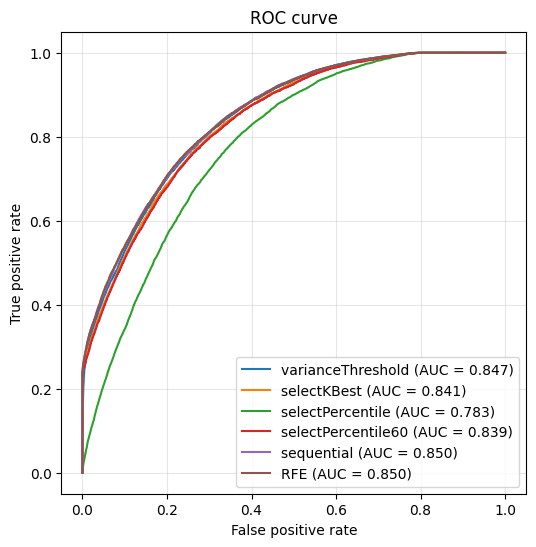

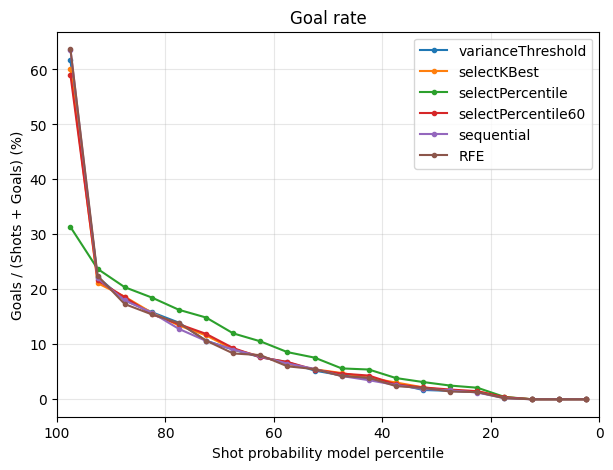

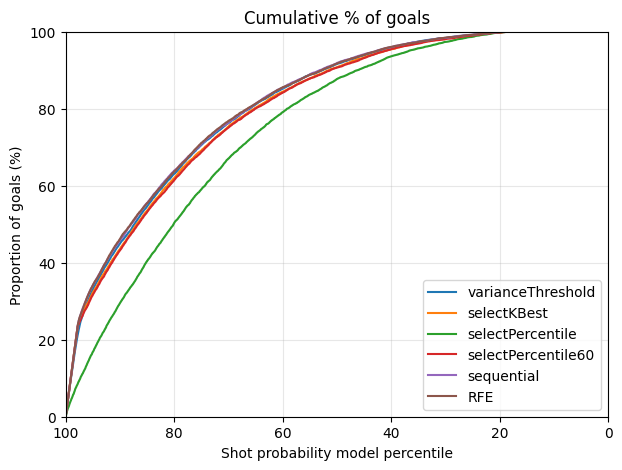

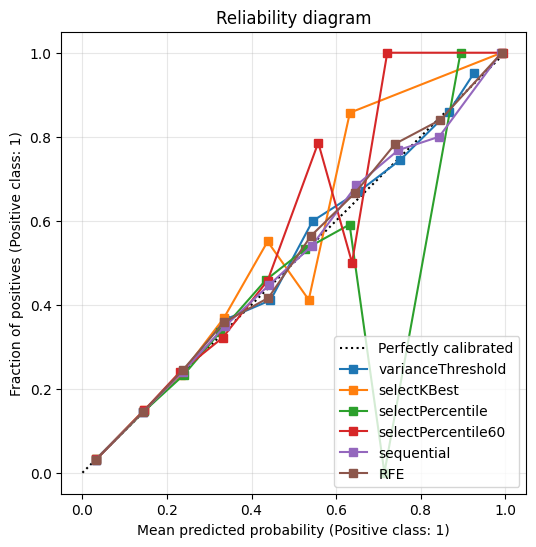

In [100]:
roc_plot(y_val,probas)
plt.show()

goal_rate_plot(y_val,probas)
plt.show()

cumulative_goals_plot(y_val,probas)
plt.show()

plot_calibration(y_val,probas)
plt.savefig(FIGURE_DIR / "XGBoost_q3_features.png", dpi=150)
plt.show()

The best feature selection is found with varianceThreshold, sequential or RFE.

- RFE : 10 features
- Sequential : 14 features
- varianceThreshold : 14 features

Let's explore more with RFE

## RFE

In [101]:
def selector_rfe(n,model):
    selector = RFE(model, n_features_to_select=n, step=1)
    X_rfe = selector.fit_transform(train, y_train)

    cols = train.columns[selector.get_support()]
    X_rfe = pd.DataFrame(X_rfe,columns=cols,index=train.index)

    model.fit(X_rfe,y_train)
    X_val_rfe = val[cols]
    probas['RFE'+str(n)] = model.predict_proba(X_val_rfe)[:, -1]

    return

In [102]:
# Reset probas
probas = {}

features = 14
while features >= 10:
    selector_rfe(features,model)
    features -= 1

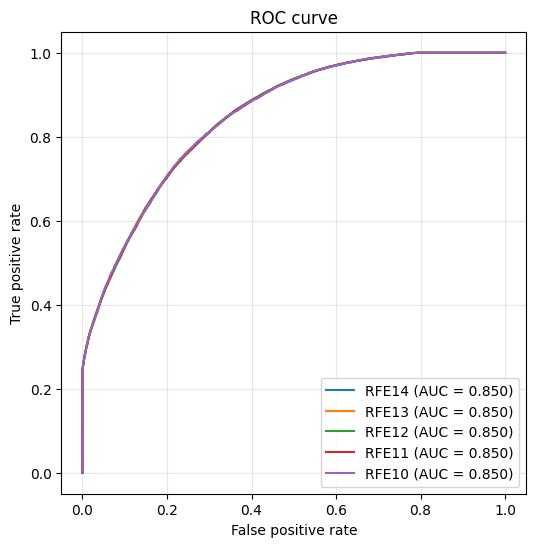

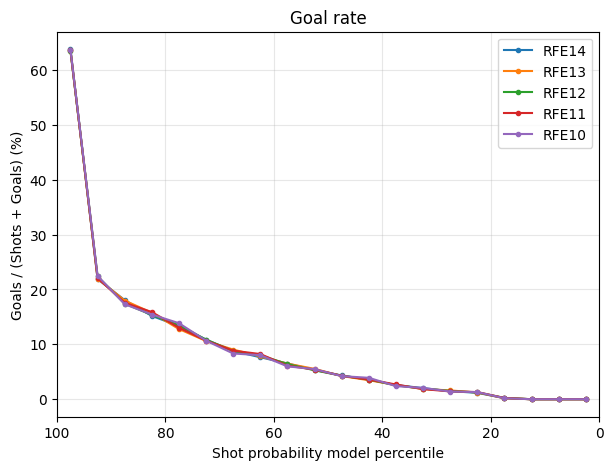

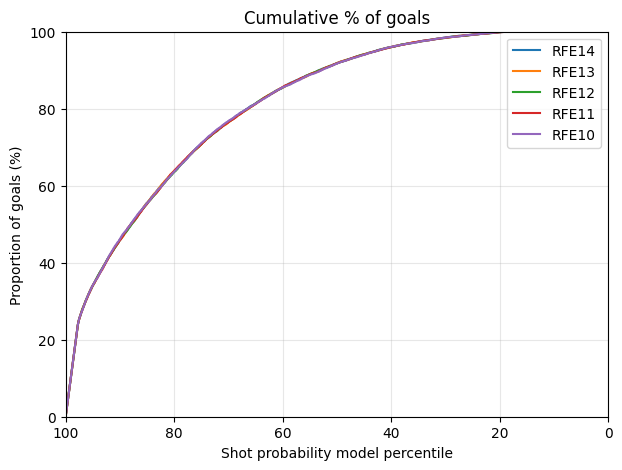

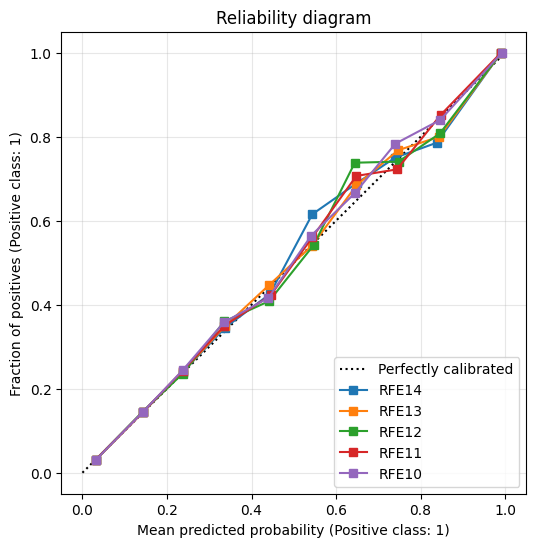

In [103]:
roc_plot(y_val,probas)
plt.show()
goal_rate_plot(y_val,probas)
plt.show()
cumulative_goals_plot(y_val,probas)
plt.show()

plot_calibration(y_val,probas)
plt.savefig(FIGURE_DIR / "XGBoost_q3_RFE14.png", dpi=150)
plt.show()

In [82]:
for p in probas.items():
    print(p[0])
    print(roc_auc_score(y_val,p[1]))

RFE14
0.8503737613173191
RFE13
0.8501610728598766
RFE12
0.8498378246073939
RFE11
0.8498966182658348
RFE10
0.8501813707761969


Really similar results.

In [104]:
# Reset probas
probas = {}

features = 10
while features > 5:
    selector_rfe(features,model)
    features -= 1

In [ ]:
for p in probas.items():
    print(p[0])
    print(roc_auc_score(y_val,p[1]))

RFE10
0.8501813707761969
RFE9
0.849462794241292
RFE8
0.847939465267697
RFE7
0.8480291993130147
RFE6
0.8452414134707236


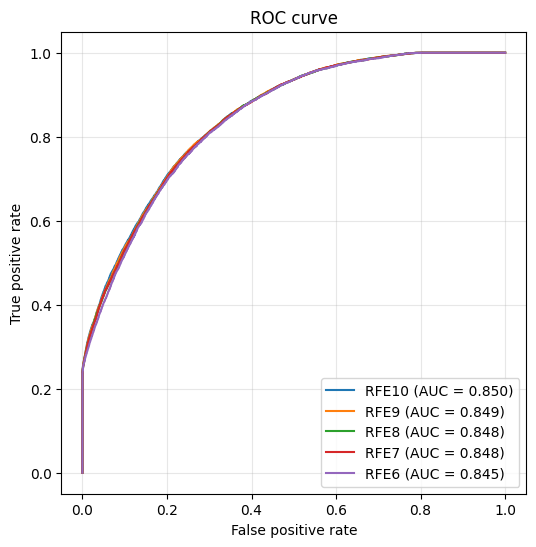

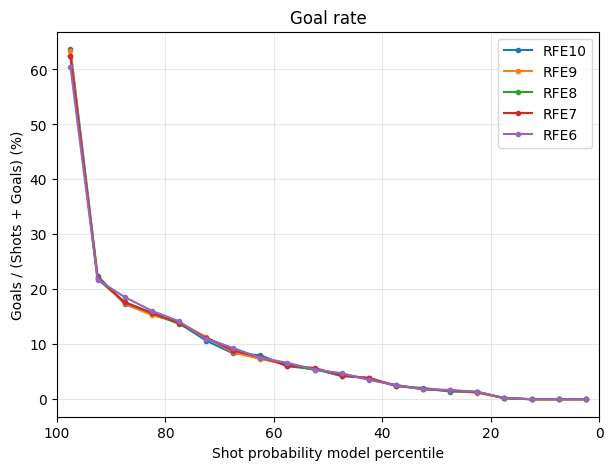

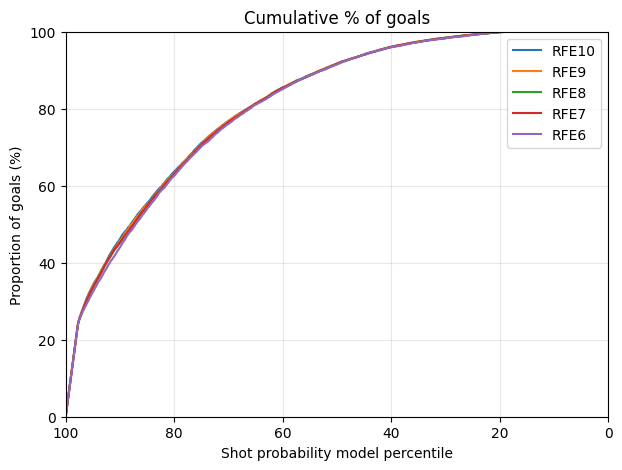

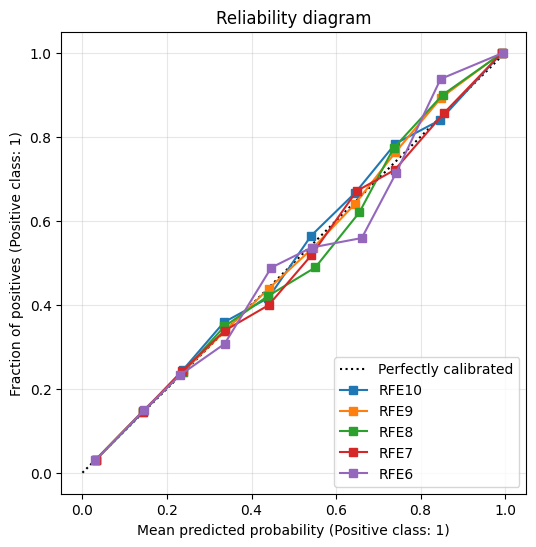

In [105]:
roc_plot(y_val,probas)
plt.show()
goal_rate_plot(y_val,probas)
plt.show()
cumulative_goals_plot(y_val,probas)
plt.show()
plot_calibration(y_val,probas)
plt.savefig(FIGURE_DIR / "XGBoost_q3_RFE10.png", dpi=150)
plt.show()

Similar results. For the reliability diagram, curve were closer to the perfect calibrated curve for the feature selection between 14 and 10 features.

## Hyperparameters tuning with the features selected

Best compromise for results and to have less features: RFE with 10 features

In [83]:
selector = RFE(model, n_features_to_select=10, step=1)
X_rfe = selector.fit_transform(train, y_train)

cols = train.columns[selector.get_support()]
X_rfe = pd.DataFrame(X_rfe,columns=cols,index=train.index)
print(cols)

Index(['game_seconds', 'period', 'distance', 'angle', 'shot_type',
       'last_event_type', 'time_from_last', 'distance_from_last', 'rebound',
       'speed'],
      dtype='object')


In [85]:
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.001],
    'subsample': [0.5, 0.7, 1.0]
}

select_hyper('roc_auc',X_rfe,param_grid,clf)

Fitting 5 folds for each of 27 candidates, totalling 135 fits
{'learning_rate': 0.1, 'max_depth': 7, 'subsample': 1.0}
0.8502057053098412


First hyperparameter tuning results were

{'learning_rate': 0.1, 'max_depth': 7, 'subsample': 1.0}
0.851315047881932